# 01 · Datos, reglas y población
**Proyecto:** variabilidad de entrada al Skinpass · Ternium Pesquería, producción 2025

**Qué hace este notebook**
1. Carga los 24 archivos del Molino Caliente 4 (MC4) y los 12 del Skinpass (SKP).
2. Audita cobertura y consistencia.
3. Aplica las reglas de limpieza fijadas antes de ver resultados.
4. Define producto y la subpoblación con destino al Skinpass.
5. Liga cada rollo del MC4 con su paso por el Skinpass.

Los demás notebooks parten de las mismas funciones (`src/ternium.py`), así que todos usan la misma población.

## 0. Configuración
Importa `src/ternium.py`, donde viven la carga de datos y las reglas de limpieza. Basta con tener el repositorio clonado: los Excel ya vienen en `data/`.

In [ ]:
# Solo en Colab: clona el repo del equipo e instala dependencias. En local no hace nada.
# El token de GitHub del equipo se guarda una vez en Colab -> 🔑 Secrets con el nombre GITHUB_TOKEN
# (con "Notebook access" activado). Si no está, lo pide aquí sin mostrarlo.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if not os.path.exists(REPO):
        try:
            from google.colab import userdata
            token = userdata.get('GITHUB_TOKEN')
        except Exception:
            from getpass import getpass
            token = getpass('Pega el token de GitHub del equipo: ')
        url = f'https://{token.strip()}@github.com/DiegoLarrieta/Entregable_Reto.git'
        r = subprocess.run(['git', 'clone', '-q', url, REPO], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError('No se pudo clonar el repo: revisa que el token sea el correcto y no haya expirado.')
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [3]:
# Configuración: busca la carpeta del repo para poder importar src/ternium.py.
import sys
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

estilo()
pd.set_option('display.max_columns', 20)

StopIteration: 

## 1. Carga
Los Excel se leen tal como los entregó Ternium, sin ediciones manuales. Cada fila del MC4 es un rollo; cada fila del Skinpass es una pieza (un rollo puede salir del Skinpass dividido en 2 o 3).

In [2]:
mc4 = cargar_mc4()
skp = cargar_skp()

print(f'MC4: {mc4.shape[0]:,} rollos · {mc4.shape[1] - 1} columnas · {mc4.Origen_Archivo.nunique()} archivos')
print(f'SKP: {skp.shape[0]:,} piezas · {skp.shape[1] - 1} columnas · {skp.Origen_Archivo.nunique()} archivos')

MC4: 149,734 rollos · 280 columnas · 24 archivos
SKP: 58,786 piezas · 208 columnas · 12 archivos


## 2. Auditoría
Revisamos tres cosas antes de analizar: que no falten periodos, que no haya rollos duplicados y que las fechas caigan en 2025.

In [3]:
# Rollos por mes real de laminación (no por el nombre del archivo).
por_mes = pd.DataFrame({
    'MC4': mc4['Fecha Inicio'].dt.to_period('M').value_counts().sort_index(),
    'Skinpass': skp['Fecha Inicio'].dt.to_period('M').value_counts().sort_index(),
}).fillna(0).astype(int)
print(por_mes.to_string())
por_mes = por_mes[por_mes.index.year == 2025]   # las pocas filas de dic-2024 son turnos que cruzan la medianoche

print('\nRollos MC4 duplicados (Material Salida):', mc4['Material Salida'].duplicated().sum())
print('Piezas SKP duplicadas (Material Salida):', skp['Material Salida'].duplicated().sum())

                MC4  Skinpass
Fecha Inicio                 
2024-12         110        39
2025-01       14238      5429
2025-02       11150      4574
2025-03       13045      5298
2025-04       11951      4992
2025-05       11827      5034
2025-06       12041      4868
2025-07       13148      4836
2025-08       12757      5369
2025-09       10731      3579
2025-10       11465      5038
2025-11       14170      4919
2025-12       13101      4811

Rollos MC4 duplicados (Material Salida): 0
Piezas SKP duplicadas (Material Salida): 0


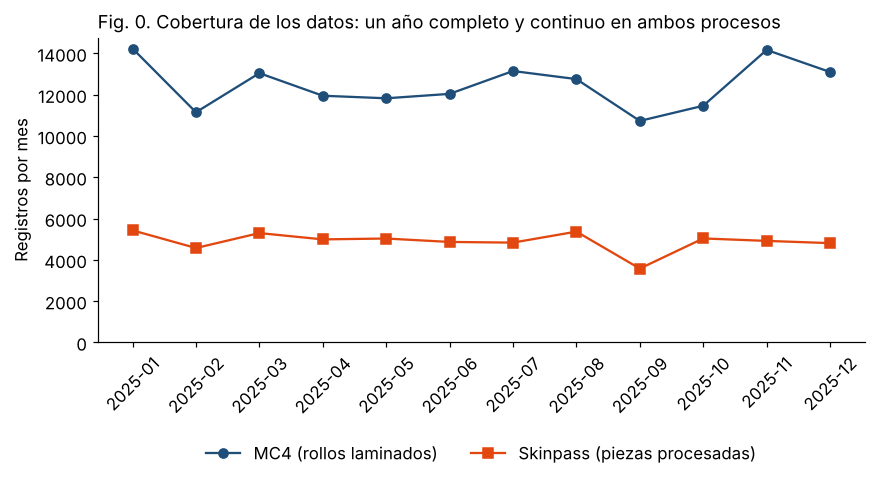

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = por_mes.index.astype(str)
ax.plot(x, por_mes.MC4, 'o-', color=COLORES['azul'], label='MC4 (rollos laminados)')
ax.plot(x, por_mes.Skinpass, 's-', color=COLORES['naranja'], label='Skinpass (piezas procesadas)')
ax.set_ylabel('Registros por mes')
ax.set_ylim(0)
ax.tick_params(axis='x', rotation=45)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2)
ax.set_title('Fig. 0. Cobertura de los datos: un año completo y continuo en ambos procesos')
guardar(fig, 'fig0_cobertura')
plt.show()

**Qué vemos.** Los dos procesos cubren los 12 meses de 2025 sin huecos. El MC4 lamina del orden de 12 mil rollos al mes y el Skinpass procesa unas 5 mil piezas; la diferencia es esperable, porque solo una parte de los rollos va al Skinpass. Algunas filas del Skinpass caen en los últimos minutos de 2024: son turnos que empezaron antes de la medianoche. No hay rollos duplicados en MC4.

## 3. Reglas de limpieza
Se fijaron **antes** de mirar resultados, para no limpiar a conveniencia.

| Regla | Decisión | Por qué |
|---|---|---|
| Destino Skinpass | `Ruta Teórica` contiene `SKP_PSQ` | Es la única marca en MC4; expresa intención, no recorrido confirmado |
| Corona válida | `Corona Salida` entre 0 y 300 µm | Hay valores físicamente imposibles (−8,741 y 8,793 µm) que dominan medias y varianzas |
| Producto | Norma \| Grado \| rango de `Espesor Objetivo` | Una versión previa usaba máximo − mínimo de tolerancia, que mide el ancho de la banda de tolerancia, no el espesor |

In [5]:
mc4 = aplicar_reglas(mc4)

c = mc4['Corona Salida']
print(f'Rollos con destino Skinpass:      {mc4.SKP.sum():,} ({mc4.SKP.mean():.1%})')
print(f'Corona faltante:                  {c.isna().sum():,}')
print(f'Corona imposible (fuera 0-300 µm): {(c.notna() & ~c.between(0, 300)).sum():,}')
print(f'Corona mínima y máxima registradas: {c.min():,.0f} y {c.max():,.0f} µm')

Rollos con destino Skinpass:      50,016 (33.4%)
Corona faltante:                  3,513
Corona imposible (fuera 0-300 µm): 5,145
Corona mínima y máxima registradas: -8,741 y 8,793 µm


**Qué vemos.** Un tercio de los rollos tiene al Skinpass en su ruta. Unos 5 mil valores de corona son imposibles y otros 3.5 mil faltan; se marcan como faltantes en lugar de borrar los rollos, para no alterar los conteos de los otros análisis.

## 4. Jerarquía de producto
"Producto" no viene en los datos: lo definimos como la combinación de norma, grado y rango de espesor objetivo. La tabla cuenta cuántos productos hay en cada subpoblación que usamos.

In [6]:
prod = mc4.groupby('Producto').agg(
    skp=('SKP', 'any'),
    consignas=('Temp Enrollado Obj', 'nunique'),
)
tabla = pd.Series({
    'Todos los productos': len(prod),
    'Con destino al Skinpass': prod.skp.sum(),
    'Con más de una consigna de temperatura': (prod.consignas > 1).sum(),
    'Con destino al Skinpass y más de una consigna': (prod.skp & (prod.consignas > 1)).sum(),
}, name='productos')
tabla.to_frame()

,productos
Todos los productos,1600
Con destino al Skinpass,846
Con más de una consigna de temperatura,259
Con destino al Skinpass y más de una consigna,183


**Qué vemos.** Hay unos 1,600 productos y la mitad tiene destino al Skinpass. (La tabla 1 de la Entrega 1 decía 1,693 porque usaba la definición vieja de rango de espesor; esta es la correcta.) Pocos reciben más de una temperatura objetivo de enrollado: esos son los únicos donde se podría comparar consignas dentro de un mismo producto (se estudia en `03_receta`).

## 5. Liga MC4 → Skinpass
La llave es `Material Entrada` del Skinpass = `Material Salida` del MC4. Con ella sabemos qué rollos pasaron realmente por el Skinpass y podemos comparar contra la ruta teórica.

In [7]:
ligadas = skp['Material Entrada'].isin(mc4['Material Salida'])
print(f'Piezas del Skinpass con su rollo de MC4: {ligadas.mean():.1%}')

mc4 = mc4.assign(PasoSKP=mc4['Material Salida'].isin(skp['Material Entrada']))
pd.crosstab(mc4.SKP, mc4.PasoSKP, margins=True,
            rownames=['Ruta teórica incluye SKP'], colnames=['Pasó por el Skinpass'])

Piezas del Skinpass con su rollo de MC4: 97.1%


Pasó por el Skinpass,False,True,All
Ruta teórica incluye SKP,,,
False,98985,733,99718
True,2606,47410,50016
All,101591,48143,149734


**Qué vemos.** 97% de las piezas del Skinpass encuentran su rollo en MC4; el resto son rollos laminados antes de 2025 o en otro molino. La ruta teórica acierta en 95% de los casos: de los 50 mil rollos que decían ir al Skinpass, unos 47 mil sí pasaron. Para el análisis del Skinpass conviene usar el recorrido real (`PasoSKP`), no la ruta teórica.

## Resumen
- Datos completos y continuos: 149,734 rollos MC4 y 58,786 piezas de Skinpass en 2025.
- Reglas de limpieza fijas: destino por ruta teórica, corona válida 0-300 µm, producto = norma | grado | rango de espesor.
- 97% de las piezas del Skinpass se ligan con su rollo de MC4, lo que permite estudiar entrada contra respuesta del Skinpass.